## Step 1: Dataset Loading and Exploratory Data Analysis (EDA)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
# Dataset location within the GitHub repository
DATA_FILE = Path("Data") / "data_banknote_authentication.txt"

# Locate the dataset relative to the working directory
file_path = None

for directory in [Path.cwd(), *Path.cwd().parents]:
    candidate = directory / DATA_FILE

    if candidate.is_file():
        file_path = candidate
        break

if file_path is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILE}. "
        "Run the notebook from inside the cloned repository "
        "and ensure the Data folder is included."
    )

# Column names
column_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

# Load dataset
df = pd.read_csv(
    file_path,
    header=None,
    names=column_names
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [3]:

# Dataset structure
print("DATASET INFORMATION")
df.info()

# Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# Class distribution
print("\nCLASS DISTRIBUTION")
print(df["class"].value_counts().sort_index())

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe())

# Feature correlations
print("\nCORRELATION MATRIX")
display(df.corr())


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

MISSING VALUES
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

DUPLICATE ROWS
24

CLASS DISTRIBUTION
class
0    762
1    610
Name: count, dtype: int64

STATISTICAL SUMMARY


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000



CORRELATION MATRIX


,variance,skewness,curtosis,entropy,class
variance,1.000000,0.264026,-0.380850,0.276817,-0.724843
skewness,0.264026,1.000000,-0.786895,-0.526321,-0.444688
curtosis,-0.380850,-0.786895,1.000000,0.318841,0.155883
entropy,0.276817,-0.526321,0.318841,1.000000,-0.023424
class,-0.724843,-0.444688,0.155883,-0.023424,1.000000


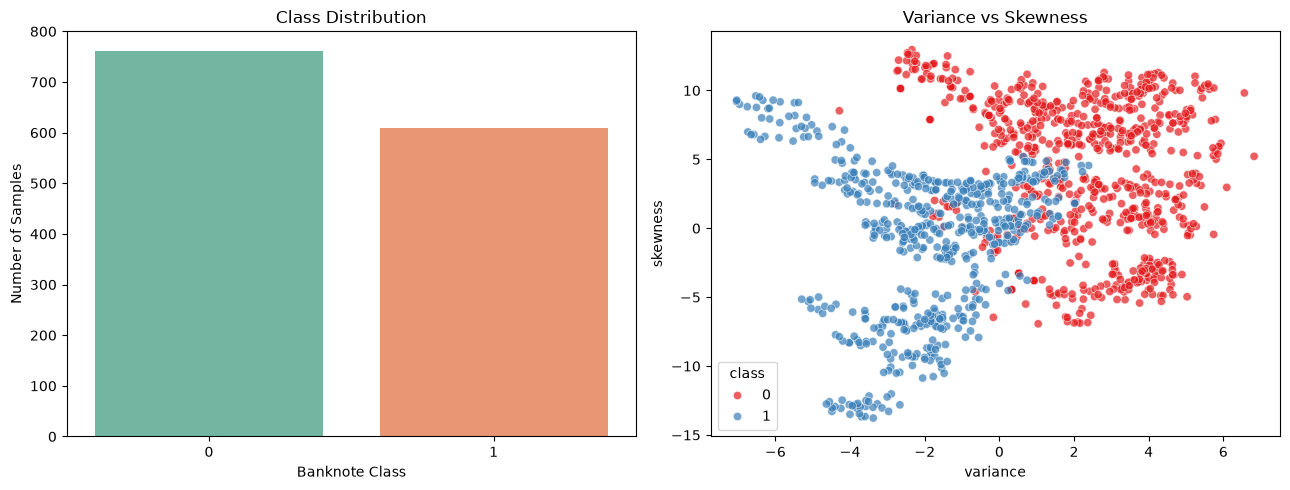

In [4]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Class distribution
sns.countplot(
    data=df,
    x="class",
    hue="class",
    palette="Set2",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Class Distribution")
axes[0].set_xlabel("Banknote Class")
axes[0].set_ylabel("Number of Samples")

# Scatter plot using the first two features
sns.scatterplot(
    data=df,
    x="variance",
    y="skewness",
    hue="class",
    palette="Set1",
    alpha=0.7,
    ax=axes[1]
)

axes[1].set_title("Variance vs Skewness")

plt.tight_layout()
plt.show()


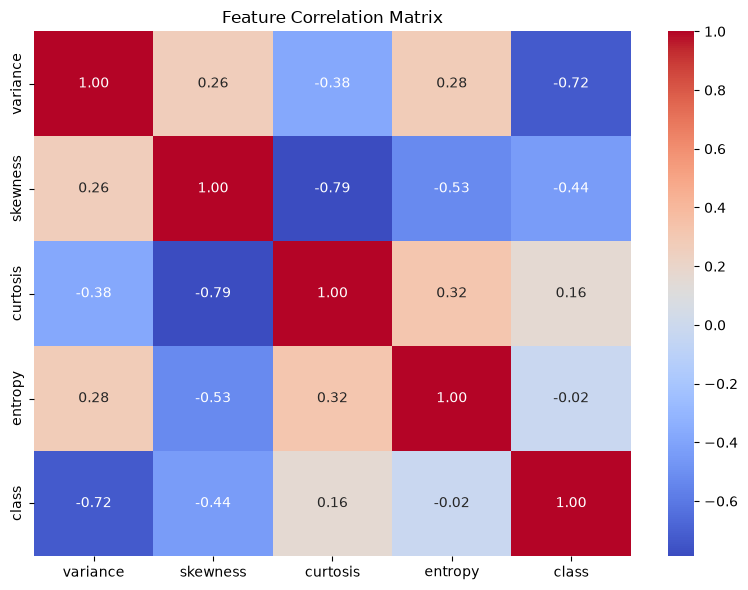

In [5]:

plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


## Creating a leakage-safe train-test split

In [7]:

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold

# Separate input features and target
feature_cols = [
    "variance",
    "skewness",
    "curtosis",
    "entropy"
]

X = df[feature_cols].copy()
y = df["class"].copy()

# Identical feature vectors get identical group IDs
groups = pd.util.hash_pandas_object(
    X, index=False
).to_numpy()

# Split into approximately 80% training and 20% testing
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True))

# Verify no feature-identical samples cross partitions
train_groups = set(groups[train_idx])
test_groups = set(groups[test_idx])

print(
    "\nDuplicate-feature leakage:",
    len(train_groups.intersection(test_groups))
)

Training shape: (1097, 4)
Testing shape: (275, 4)

Training class distribution:
class
0    0.55515
1    0.44485
Name: proportion, dtype: float64

Testing class distribution:
class
0    0.556364
1    0.443636
Name: proportion, dtype: float64

Duplicate-feature leakage: 0


## Step 2: Decision Tree from Scratch — Gini Impurity and Entropy

In [8]:

import numpy as np

def gini_impurity(y):
    y = np.asarray(y)

    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


def entropy(y):
    y = np.asarray(y)

    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))


# Test on training labels
print("Training Gini:", gini_impurity(y_train))
print("Training Entropy:", entropy(y_train))

# Test with a pure node
pure_node = np.array([0, 0, 0, 0])

print("\nPure Node Gini:", gini_impurity(pure_node))
print("Pure Node Entropy:", entropy(pure_node))


Training Gini: 0.4939168645074119
Training Entropy: 0.9912060080005995

Pure Node Gini: 0.0
Pure Node Entropy: -0.0


## Step 3: Finding the Optimal Split Using Gini Impurity

In [10]:

def best_split(X, y, min_samples_leaf=1):

    X = np.asarray(X)
    y = np.asarray(y)

    n_samples, n_features = X.shape

    best_gain = 0.0
    best_feature = None
    best_threshold = None

    parent_gini = gini_impurity(y)

    # Examine every feature
    for feature in range(n_features):

        values = np.unique(X[:, feature])

        # Generate candidate thresholds
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:

            # Split observations
            left_mask = X[:, feature] <= threshold
            right_mask = ~left_mask

            y_left = y[left_mask]
            y_right = y[right_mask]

            n_left = len(y_left)
            n_right = len(y_right)

            # Avoid creating undersized leaves
            if (
                n_left < min_samples_leaf
                or n_right < min_samples_leaf
            ):
                continue

            # Calculate child impurities
            left_gini = gini_impurity(y_left)
            right_gini = gini_impurity(y_right)

            # Weighted Gini
            weighted_gini = (
                (n_left / n_samples) * left_gini
                + (n_right / n_samples) * right_gini
            )

            # Improvement in impurity
            gain = parent_gini - weighted_gini

            # Retain the best split
            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    return best_feature, best_threshold, best_gain

In [11]:

feature_names = X_train.columns.tolist()

feature, threshold, gain = best_split(
    X_train.to_numpy(),
    y_train.to_numpy()
)

print("Best Feature:", feature_names[feature])
print("Best Threshold:", threshold)
print("Gini Reduction:", gain)

print("\nRoot Node Condition:")
print(f"If {feature_names[feature]} <= {threshold:.4f}")


Best Feature: variance
Best Threshold: 0.321235
Gini Reduction: 0.24806402462777177

Root Node Condition:
If variance <= 0.3212


## Step 4: Recursive Decision Tree Construction and Stopping Criteria

In [12]:

import numpy as np

class Node:
    def __init__(
        self,
        feature=None,
        threshold=None,
        left=None,
        right=None,
        value=None,
        n_samples=None,
        impurity=None
    ):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
        self.n_samples = n_samples
        self.impurity = impurity

    def is_leaf(self):
        return self.value is not None


class DecisionTreeScratch:

    def __init__(
        self,
        max_depth=3,
        min_samples_split=2,
        min_samples_leaf=1,
        min_impurity_decrease=0.0
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.root = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel()

        self.root = self._grow_tree(X, y, depth=0)
        return self

    def _grow_tree(self, X, y, depth):

        n_samples = len(y)
        n_classes = len(np.unique(y))

        impurity = gini_impurity(y)

        # Stopping conditions
        stop = (
            depth >= self.max_depth
            or n_classes == 1
            or n_samples < self.min_samples_split
            or n_samples < 2 * self.min_samples_leaf
        )

        if stop:
            return self._create_leaf(y, impurity)

        # Find best split
        feature, threshold, gain = best_split(
            X, y,
            min_samples_leaf=self.min_samples_leaf
        )

        # Stop if no useful split is available
        if (
            feature is None
            or gain <= 0
            or gain < self.min_impurity_decrease
        ):
            return self._create_leaf(y, impurity)

        # Split dataset
        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        # Recursively construct children
        left_child = self._grow_tree(
            X[left_mask], y[left_mask], depth + 1
        )

        right_child = self._grow_tree(
            X[right_mask], y[right_mask], depth + 1
        )

        return Node(
            feature=feature,
            threshold=threshold,
            left=left_child,
            right=right_child,
            n_samples=n_samples,
            impurity=impurity
        )

    def _create_leaf(self, y, impurity):

        classes, counts = np.unique(
            y, return_counts=True
        )

        majority_class = classes[np.argmax(counts)]

        return Node(
            value=majority_class,
            n_samples=len(y),
            impurity=impurity
        )

    def _predict_one(self, x, node):

        if node.is_leaf():
            return node.value

        if x[node.feature] <= node.threshold:
            return self._predict_one(x, node.left)

        return self._predict_one(x, node.right)

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        return np.array([
            self._predict_one(x, self.root)
            for x in X
        ])


In [13]:

# Initialize the Decision Tree
tree = DecisionTreeScratch(
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1
)

# Train using training data only
tree.fit(X_train.to_numpy(), y_train.to_numpy())

print("Decision Tree trained successfully!")

print("\nRoot feature:",
      X_train.columns[tree.root.feature])

print("Root threshold:", tree.root.threshold)

print("Root Gini:", tree.root.impurity)


Decision Tree trained successfully!

Root feature: variance
Root threshold: 0.321235
Root Gini: 0.4939168645074119


## Step 5: Visualizing the Learned Decision Rules

In [14]:

def print_tree(node, feature_names, depth=0):

    indent = "    " * depth

    if node.is_leaf():
        print(
            f"{indent}Predict Class {node.value} "
            f"| Samples: {node.n_samples} "
            f"| Gini: {node.impurity:.4f}"
        )
        return

    feature_name = feature_names[node.feature]

    print(
        f"{indent}IF {feature_name} <= {node.threshold:.4f} "
        f"| Gini: {node.impurity:.4f} "
        f"| Samples: {node.n_samples}"
    )

    print(f"{indent}  TRUE:")
    print_tree(node.left, feature_names, depth + 1)

    print(f"{indent}  FALSE:")
    print_tree(node.right, feature_names, depth + 1)


print_tree(
    tree.root,
    X_train.columns.tolist()
)


IF variance <= 0.3212 | Gini: 0.4939 | Samples: 1097
  TRUE:
    IF skewness <= 7.5653 | Gini: 0.3056 | Samples: 526
      TRUE:
        IF skewness <= 5.8654 | Gini: 0.1299 | Samples: 444
          TRUE:
            Predict Class 1 | Samples: 415 | Gini: 0.0874
          FALSE:
            Predict Class 1 | Samples: 29 | Gini: 0.4851
      FALSE:
        IF variance <= -4.7260 | Gini: 0.2832 | Samples: 82
          TRUE:
            Predict Class 1 | Samples: 14 | Gini: 0.0000
          FALSE:
            Predict Class 0 | Samples: 68 | Gini: 0.0000
  FALSE:
    IF curtosis <= -4.3861 | Gini: 0.1908 | Samples: 571
      TRUE:
        IF variance <= 3.3041 | Gini: 0.3343 | Samples: 33
          TRUE:
            Predict Class 1 | Samples: 26 | Gini: 0.0000
          FALSE:
            Predict Class 0 | Samples: 7 | Gini: 0.0000
      FALSE:
        IF variance <= 1.5922 | Gini: 0.1216 | Samples: 538
          TRUE:
            Predict Class 0 | Samples: 151 | Gini: 0.3416
          FAL

## Step 6: Model Evaluation — Training Accuracy, Testing Accuracy and Classification Metrics

In [15]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predictions on training data
y_train_pred = tree.predict(X_train.to_numpy())

# Predictions on unseen testing data
y_test_pred = tree.predict(X_test.to_numpy())

# Calculate accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("DECISION TREE FROM SCRATCH")
print("-------------------------")

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Testing Accuracy:  {test_accuracy * 100:.2f}%")

print(f"Accuracy Gap: {(train_accuracy - test_accuracy) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))


DECISION TREE FROM SCRATCH
-------------------------
Training Accuracy: 93.98%
Testing Accuracy:  93.45%
Accuracy Gap: 0.53%

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.94       153
           1       0.93      0.92      0.93       122

    accuracy                           0.93       275
   macro avg       0.93      0.93      0.93       275
weighted avg       0.93      0.93      0.93       275


Confusion Matrix:
[[145   8]
 [ 10 112]]


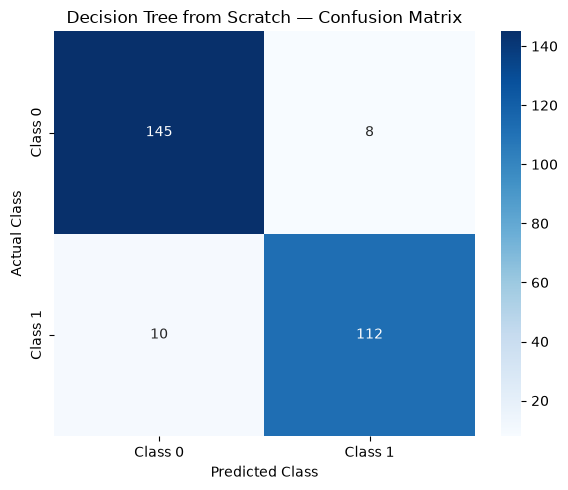

In [16]:

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Decision Tree from Scratch — Confusion Matrix")

plt.tight_layout()
plt.show()


## Step 9: Decision Tree Hyperparameter Tuning Using Cross-Validation

In [17]:

import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold
)

# Search for promising hyperparameters
param_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, 12],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

# Keep identical feature vectors together during CV
groups_train = pd.util.hash_pandas_object(
    X_train, index=False
).to_numpy()

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    estimator=DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    ),
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("Best Parameters:", grid.best_params_)
print(
    "Best Cross-Validation Accuracy:",
    round(grid.best_score_ * 100, 2),
    "%"
)


Best Parameters: {'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Cross-Validation Accuracy: 98.63 %


In [18]:

best_params = grid.best_params_

optimized_tree = DecisionTreeScratch(
    max_depth=best_params["max_depth"],
    min_samples_split=best_params["min_samples_split"],
    min_samples_leaf=best_params["min_samples_leaf"]
)

optimized_tree.fit(
    X_train.to_numpy(),
    y_train.to_numpy()
)

print("Optimized manual tree trained successfully!")


Optimized manual tree trained successfully!


In [19]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

train_pred = optimized_tree.predict(
    X_train.to_numpy()
)

test_pred = optimized_tree.predict(
    X_test.to_numpy()
)

train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, test_pred)

print("OPTIMIZED DECISION TREE")
print("--------------------------")

print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Testing Accuracy: {test_acc * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))


OPTIMIZED DECISION TREE
--------------------------
Training Accuracy: 100.00%
Testing Accuracy: 98.18%

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       153
           1       0.98      0.98      0.98       122

    accuracy                           0.98       275
   macro avg       0.98      0.98      0.98       275
weighted avg       0.98      0.98      0.98       275


Confusion Matrix:
[[150   3]
 [  2 120]]


## Step 10: Decision Boundary Visualization of the Decision Tree

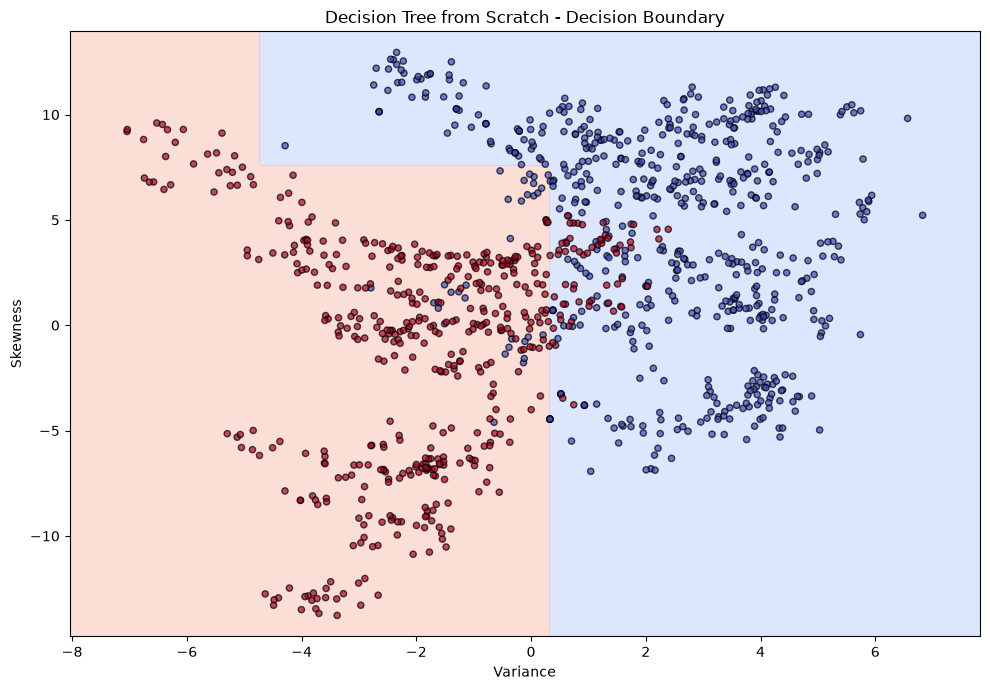

In [20]:

import numpy as np
import matplotlib.pyplot as plt

# Select two features for 2D visualization
features_2d = ["variance", "skewness"]

X_train_2d = X_train[features_2d].to_numpy()
y_train_array = y_train.to_numpy()

# Train a separate manual Decision Tree
tree_2d = DecisionTreeScratch(
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1
)

tree_2d.fit(X_train_2d, y_train_array)

# Create a mesh grid
x_min = X_train_2d[:, 0].min() - 1
x_max = X_train_2d[:, 0].max() + 1

y_min = X_train_2d[:, 1].min() - 1
y_max = X_train_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predict classes across the grid
grid_points = np.c_[xx.ravel(), yy.ravel()]

Z = tree_2d.predict(grid_points)
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, Z,
    levels=[-0.5, 0.5, 1.5],
    cmap="coolwarm",
    alpha=0.3
)

plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_train_array,
    cmap="coolwarm",
    edgecolors="black",
    s=20,
    alpha=0.7
)

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Decision Tree from Scratch - Decision Boundary")

plt.tight_layout()
plt.show()


## Step 11: Visualization of the Decision Tree Structure from Scratch

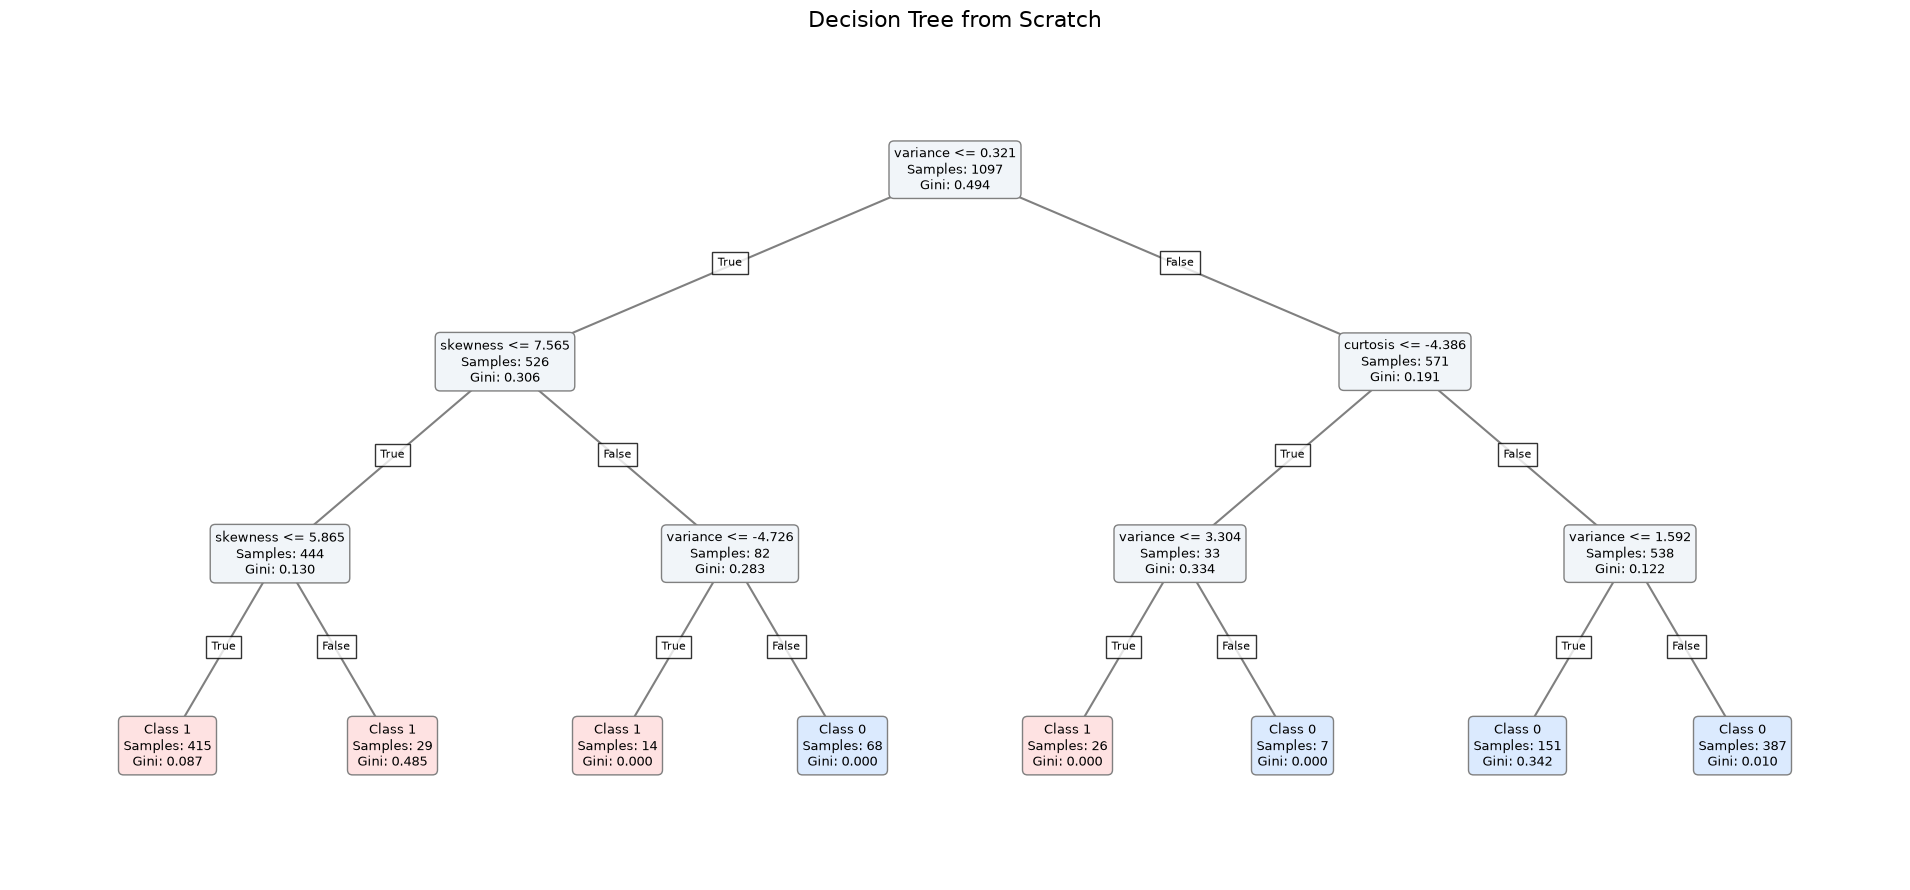

In [21]:

import matplotlib.pyplot as plt

def visualize_manual_tree(tree, feature_names):

    positions = {}
    leaf_index = [0]

    # Calculate positions of all nodes
    def assign_positions(node, depth=0):

        if node.is_leaf():
            x = leaf_index[0]
            leaf_index[0] += 1

        else:
            left_x = assign_positions(node.left, depth + 1)
            right_x = assign_positions(node.right, depth + 1)

            x = (left_x + right_x) / 2

        positions[id(node)] = (x, depth)
        return x

    assign_positions(tree.root)

    fig, ax = plt.subplots(
        figsize=(max(16, leaf_index[0] * 2.4), 9)
    )

    def draw_node(node):

        x, depth = positions[id(node)]

        if node.is_leaf():

            label = (
                f"Class {node.value}\n"
                f"Samples: {node.n_samples}\n"
                f"Gini: {node.impurity:.3f}"
            )

            color = "#dbeafe" if node.value == 0 else "#fee2e2"

        else:

            label = (
                f"{feature_names[node.feature]} "
                f"<= {node.threshold:.3f}\n"
                f"Samples: {node.n_samples}\n"
                f"Gini: {node.impurity:.3f}"
            )

            color = "#f1f5f9"

            for child, branch in [
                (node.left, "True"),
                (node.right, "False")
            ]:

                cx, cy = positions[id(child)]

                ax.plot(
                    [x, cx],
                    [depth, cy],
                    color="gray",
                    linewidth=1.5,
                    zorder=1
                )

                ax.text(
                    (x + cx) / 2,
                    (depth + cy) / 2,
                    branch,
                    fontsize=8,
                    ha="center",
                    bbox=dict(facecolor="white", alpha=0.8),
                    zorder=2
                )

                draw_node(child)

        ax.text(
            x, depth, label,
            ha="center",
            va="center",
            fontsize=9,
            bbox=dict(
                boxstyle="round,pad=0.4",
                facecolor=color,
                edgecolor="gray"
            ),
            zorder=3
        )

    draw_node(tree.root)

    max_depth = max(
        depth for _, depth in positions.values()
    )

    ax.set_xlim(-0.7, leaf_index[0] - 0.3)
    ax.set_ylim(max_depth + 0.7, -0.7)
    ax.axis("off")

    plt.title("Decision Tree from Scratch", fontsize=16)
    plt.tight_layout()
    plt.show()


# Visualize our original depth-3 manual tree
visualize_manual_tree(
    tree,
    X_train.columns.tolist()
)


## Step 12: Manual Decision Tree vs Scikit-learn — Performance Comparison

In [22]:

import time
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Same hyperparameters for a fair comparison
params = {
    "max_depth": 3,
    "min_samples_split": 2,
    "min_samples_leaf": 1
}

# ---------------- MANUAL TREE ----------------

manual_tree = DecisionTreeScratch(**params)

start = time.perf_counter()
manual_tree.fit(X_train.to_numpy(), y_train.to_numpy())
manual_train_time = time.perf_counter() - start

start = time.perf_counter()
manual_pred = manual_tree.predict(X_test.to_numpy())
manual_predict_time = time.perf_counter() - start

# ---------------- SCIKIT-LEARN TREE ----------------

sk_tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=42,
    **params
)

start = time.perf_counter()
sk_tree.fit(X_train, y_train)
sk_train_time = time.perf_counter() - start

start = time.perf_counter()
sk_pred = sk_tree.predict(X_test)
sk_predict_time = time.perf_counter() - start

# ---------------- COMPARISON ----------------

results = pd.DataFrame({
    "Model": [
        "Manual Decision Tree",
        "Scikit-learn Decision Tree"
    ],
    "Accuracy": [
        accuracy_score(y_test, manual_pred),
        accuracy_score(y_test, sk_pred)
    ],
    "Precision": [
        precision_score(y_test, manual_pred),
        precision_score(y_test, sk_pred)
    ],
    "Recall": [
        recall_score(y_test, manual_pred),
        recall_score(y_test, sk_pred)
    ],
    "F1-score": [
        f1_score(y_test, manual_pred),
        f1_score(y_test, sk_pred)
    ],
    "Training Time (s)": [
        manual_train_time,
        sk_train_time
    ],
    "Prediction Time (s)": [
        manual_predict_time,
        sk_predict_time
    ]
})

display(results.round(4))

print("Prediction disagreements:",
      np.sum(manual_pred != sk_pred))

print("Manual root threshold:",
      manual_tree.root.threshold)

print("Scikit-learn root threshold:",
      sk_tree.tree_.threshold[0])


,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Decision Tree,0.9345,0.9333,0.918,0.9256,0.5758,0.0003
1,Scikit-learn Decision Tree,0.9345,0.9333,0.918,0.9256,0.0117,0.0014


Prediction disagreements: 0
Manual root threshold: 0.321235
Scikit-learn root threshold: 0.3212350010871887


## Step 13: Feature Scaling and Label Encoding for Linear SVM

In [23]:

import numpy as np

# Convert existing train-test sets to NumPy
X_train_svm = X_train.to_numpy(dtype=float)
X_test_svm = X_test.to_numpy(dtype=float)

# Convert class labels from {0, 1} to {-1, +1}
y_train_svm = np.where(y_train.to_numpy() == 0, -1, 1)
y_test_svm = np.where(y_test.to_numpy() == 0, -1, 1)

# Calculate statistics on training data ONLY
mean = X_train_svm.mean(axis=0)
std = X_train_svm.std(axis=0)

# Prevent division by zero
std[std == 0] = 1

# Standardize both sets using training statistics
X_train_svm = (X_train_svm - mean) / std
X_test_svm = (X_test_svm - mean) / std

print("Training Shape:", X_train_svm.shape)
print("Testing Shape:", X_test_svm.shape)

print("\nTraining Feature Means:")
print(X_train_svm.mean(axis=0))

print("\nTraining Feature Standard Deviations:")
print(X_train_svm.std(axis=0))

print("\nUnique SVM Labels:")
print(np.unique(y_train_svm))


Training Shape: (1097, 4)
Testing Shape: (275, 4)

Training Feature Means:
[ 5.18171548e-17  2.59085774e-17  0.00000000e+00 -8.09643044e-17]

Training Feature Standard Deviations:
[1. 1. 1. 1.]

Unique SVM Labels:
[-1  1]


## Step 14: Implementing Hinge Loss and Subgradient Calculation

In [24]:

import numpy as np

def hinge_loss(y_true, scores):
    margins = y_true * scores
    losses = np.maximum(0, 1 - margins)
    return np.mean(losses)


def svm_objective(X, y, w, b, C=1.0):

    scores = X @ w + b

    # Classification loss
    loss = hinge_loss(y, scores)

    # L2 regularization
    regularization = 0.5 * np.dot(w, w)

    return regularization + C * loss


In [25]:

# Example with four observations
y_example = np.array([1, 1, -1, -1])

scores_example = np.array([2.0, 0.5, -0.5, 1.0])

loss = hinge_loss(y_example, scores_example)

print("Mean Hinge Loss:", loss)


Mean Hinge Loss: 0.75


In [26]:

def svm_subgradients(X, y, w, b, C=1.0):

    n_samples = X.shape[0]

    # Decision scores
    scores = X @ w + b

    # Functional margins
    margins = y * scores

    # Samples violating the margin
    violations = margins < 1

    # Weight subgradient
    dw = w - (C / n_samples) * (
        X[violations].T @ y[violations]
    )

    # Bias subgradient
    db = -(C / n_samples) * np.sum(
        y[violations]
    )

    return dw, db


In [27]:

# Initialize weights and bias
n_features = X_train_svm.shape[1]

w = np.zeros(n_features)
b = 0.0

C = 1.0

# Calculate initial objective
initial_loss = svm_objective(
    X_train_svm,
    y_train_svm,
    w,
    b,
    C
)

# Calculate initial subgradients
dw, db = svm_subgradients(
    X_train_svm,
    y_train_svm,
    w,
    b,
    C
)

print("Initial Weights:", w)
print("Initial Bias:", b)
print("Initial Objective:", initial_loss)

print("\nWeight Subgradients:", dw)
print("Bias Subgradient:", db)


Initial Weights: [0. 0. 0. 0.]
Initial Bias: 0.0
Initial Objective: 1.0

Weight Subgradients: [ 0.7200144   0.45184478 -0.1598603   0.02646911]
Bias Subgradient: 0.11030082041932543


In [28]:

learning_rate = 0.01

# First gradient descent update
w_new = w - learning_rate * dw
b_new = b - learning_rate * db

# Calculate objective after update
new_loss = svm_objective(
    X_train_svm,
    y_train_svm,
    w_new,
    b_new,
    C
)

print("Initial Objective:", initial_loss)
print("Objective After Update:", new_loss)

print("\nUpdated Weights:", w_new)
print("Updated Bias:", b_new)


Initial Objective: 1.0
Objective After Update: 0.9924273756243698

Updated Weights: [-0.00720014 -0.00451845  0.0015986  -0.00026469]
Updated Bias: -0.0011030082041932543


## Step 15: Linear SVM Training Using Batch Subgradient Descent

In [29]:

class LinearSVMScratch:

    def __init__(self, learning_rate=0.01, C=1.0, n_iters=2000):
        self.learning_rate = learning_rate
        self.C = C
        self.n_iters = n_iters

        self.w = None
        self.b = 0.0
        self.loss_history = []

    def fit(self, X, y):

        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel()

        if not np.all(np.isin(y, [-1, 1])):
            raise ValueError("Labels must be -1 or +1")

        n_samples, n_features = X.shape

        # Initialize
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.loss_history = []

        # Save initial objective
        initial_loss = svm_objective(
            X, y, self.w, self.b, self.C
        )
        self.loss_history.append(initial_loss)

        for iteration in range(self.n_iters):

            # Calculate subgradients
            dw, db = svm_subgradients(
                X, y, self.w, self.b, self.C
            )

            # Update parameters
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

            # Calculate objective after update
            loss = svm_objective(
                X, y, self.w, self.b, self.C
            )

            self.loss_history.append(loss)

            # Display progress
            if (iteration + 1) % 200 == 0:
                print(
                    f"Iteration {iteration + 1}: "
                    f"Objective = {loss:.6f}"
                )

        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.w + self.b

    def predict(self, X):
        scores = self.decision_function(X)
        return np.where(scores >= 0, 1, -1)


In [30]:

# Initialize our manual Linear SVM
manual_svm = LinearSVMScratch(
    learning_rate=0.01,
    C=1.0,
    n_iters=2000
)

# Train using all four standardized features
manual_svm.fit(X_train_svm, y_train_svm)

print("\nTraining completed!")

print("\nLearned Weights:")
print(manual_svm.w)

print("\nLearned Bias:")
print(manual_svm.b)

print("\nFinal Objective:")
print(manual_svm.loss_history[-1])


Iteration 200: Objective = 0.681249
Iteration 400: Objective = 0.678590
Iteration 600: Objective = 0.678410
Iteration 800: Objective = 0.678396
Iteration 1000: Objective = 0.678390
Iteration 1200: Objective = 0.678387
Iteration 1400: Objective = 0.678387
Iteration 1600: Objective = 0.678387
Iteration 1800: Objective = 0.678387
Iteration 2000: Objective = 0.678387

Training completed!

Learned Weights:
[-0.50602751 -0.28338867 -0.02424234 -0.03837986]

Learned Bias:
-0.27030082041932263

Final Objective:
0.6783865336929289


## Step 16: SVM Training Convergence Analysis

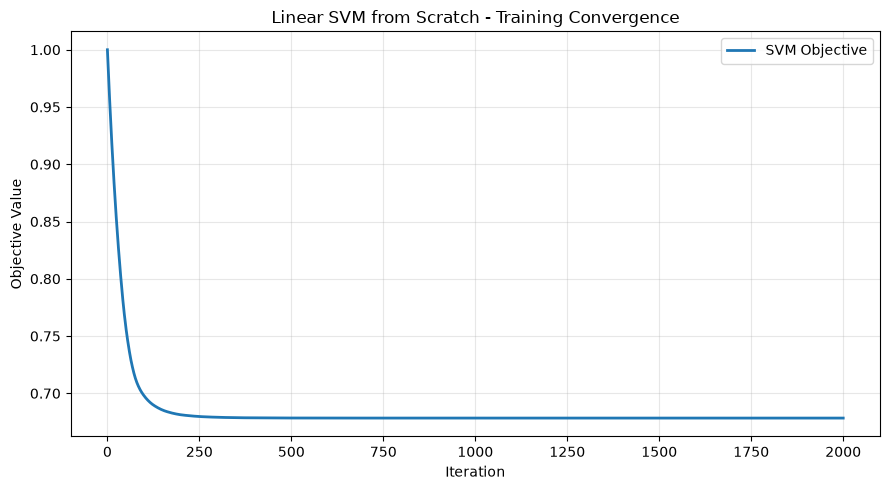

In [31]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    manual_svm.loss_history,
    linewidth=2,
    label="SVM Objective"
)

plt.xlabel("Iteration")
plt.ylabel("Objective Value")
plt.title("Linear SVM from Scratch - Training Convergence")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Step 17: Linear SVM Classification Performance

In [32]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predictions using manual SVM
svm_train_pred = manual_svm.predict(X_train_svm)
svm_test_pred = manual_svm.predict(X_test_svm)

# Accuracy
train_acc = accuracy_score(y_train_svm, svm_train_pred)
test_acc = accuracy_score(y_test_svm, svm_test_pred)

print("LINEAR SVM FROM SCRATCH")
print("-----------------------------")

print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Testing Accuracy:  {test_acc * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test_svm, svm_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_svm, svm_test_pred))


LINEAR SVM FROM SCRATCH
-----------------------------
Training Accuracy: 85.87%
Testing Accuracy:  85.82%

Classification Report:
              precision    recall  f1-score   support

          -1       0.81      0.97      0.88       153
           1       0.96      0.71      0.82       122

    accuracy                           0.86       275
   macro avg       0.88      0.84      0.85       275
weighted avg       0.87      0.86      0.85       275


Confusion Matrix:
[[149   4]
 [ 35  87]]


## Step 19: Linear SVM Decision Boundary, Margins, and Margin Violations

In [33]:

# Select two features for visualization
features_2d = ["variance", "skewness"]

X_train_2d_raw = X_train[features_2d].to_numpy(dtype=float)
X_test_2d_raw = X_test[features_2d].to_numpy(dtype=float)

# Scale using training-set statistics only
mean_2d = X_train_2d_raw.mean(axis=0)
std_2d = X_train_2d_raw.std(axis=0)
std_2d[std_2d == 0] = 1

X_train_2d_svm = (X_train_2d_raw - mean_2d) / std_2d
X_test_2d_svm = (X_test_2d_raw - mean_2d) / std_2d

# Train a separate 2D SVM
svm_2d = LinearSVMScratch(
    learning_rate=0.01,
    C=1.0,
    n_iters=2000
)

svm_2d.fit(X_train_2d_svm, y_train_svm)

print("\n2D SVM Weights:", svm_2d.w)
print("2D SVM Bias:", svm_2d.b)

print(
    "2D Test Accuracy:",
    accuracy_score(
        y_test_svm,
        svm_2d.predict(X_test_2d_svm)
    )
)


Iteration 200: Objective = 0.682585
Iteration 400: Objective = 0.680073
Iteration 600: Objective = 0.679799
Iteration 800: Objective = 0.679761
Iteration 1000: Objective = 0.679745
Iteration 1200: Objective = 0.679739
Iteration 1400: Objective = 0.679736
Iteration 1600: Objective = 0.679736
Iteration 1800: Objective = 0.679736
Iteration 2000: Objective = 0.679736

2D SVM Weights: [-0.49975888 -0.27085928]
2D SVM Bias: -0.28647219690063475
2D Test Accuracy: 0.850909090909091


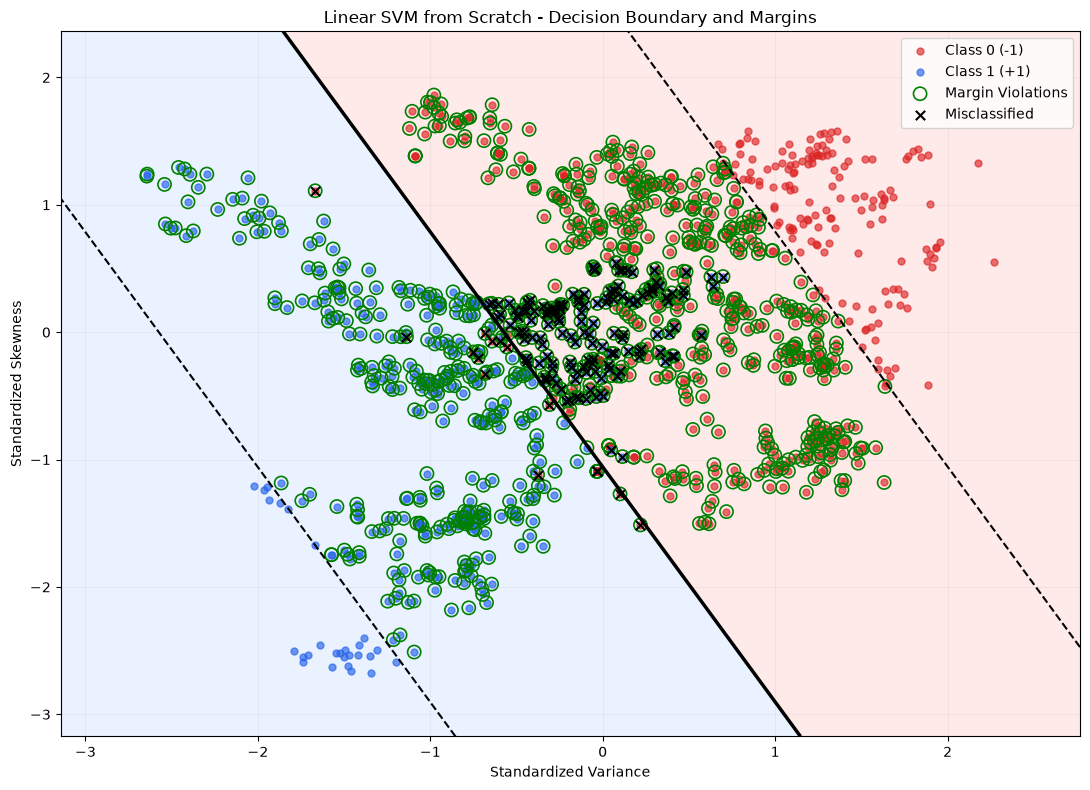

Total training samples: 1097
Margin violations: 922
Misclassified samples: 165


In [34]:

import numpy as np
import matplotlib.pyplot as plt

# Generate a mesh grid in scaled feature space
x_min = X_train_2d_svm[:, 0].min() - 0.5
x_max = X_train_2d_svm[:, 0].max() + 0.5
y_min = X_train_2d_svm[:, 1].min() - 0.5
y_max = X_train_2d_svm[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = svm_2d.decision_function(grid).reshape(xx.shape)

# Calculate functional margins
scores = svm_2d.decision_function(X_train_2d_svm)
margins = y_train_svm * scores

violations = margins < 1
misclassified = margins < 0

plt.figure(figsize=(11, 8))

# Decision regions
plt.contourf(
    xx, yy, Z,
    levels=[-1e9, 0, 1e9],
    colors=["#ffdddd", "#dbeafe"],
    alpha=0.6
)

# Decision boundary and margins
plt.contour(
    xx, yy, Z,
    levels=[-1, 0, 1],
    colors="black",
    linestyles=["dashed", "solid", "dashed"],
    linewidths=[1.5, 2.5, 1.5]
)

# Actual Class 0 (-1)
mask_0 = y_train_svm == -1

plt.scatter(
    X_train_2d_svm[mask_0, 0],
    X_train_2d_svm[mask_0, 1],
    c="#dc2626",
    s=25,
    alpha=0.65,
    label="Class 0 (-1)"
)

# Actual Class 1 (+1)
mask_1 = y_train_svm == 1

plt.scatter(
    X_train_2d_svm[mask_1, 0],
    X_train_2d_svm[mask_1, 1],
    c="#2563eb",
    s=25,
    alpha=0.65,
    label="Class 1 (+1)"
)

# Highlight margin violations
plt.scatter(
    X_train_2d_svm[violations, 0],
    X_train_2d_svm[violations, 1],
    s=90,
    facecolors="none",
    edgecolors="green",
    linewidths=1.2,
    label="Margin Violations"
)

# Highlight misclassified samples
plt.scatter(
    X_train_2d_svm[misclassified, 0],
    X_train_2d_svm[misclassified, 1],
    marker="x",
    c="black",
    s=45,
    label="Misclassified"
)

plt.xlabel("Standardized Variance")
plt.ylabel("Standardized Skewness")
plt.title("Linear SVM from Scratch - Decision Boundary and Margins")

plt.legend()
plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()

print("Total training samples:", len(y_train_svm))
print("Margin violations:", np.sum(violations))
print("Misclassified samples:", np.sum(misclassified))


## Step 21: Effect of Regularization Parameter C on Linear SVM

In [35]:

import numpy as np
import pandas as pd
import io
from contextlib import redirect_stdout

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score

# Original unscaled 2D training features
X_cv = X_train[
    ["variance", "skewness"]
].to_numpy(dtype=float)

y_cv = y_train_svm.copy()

# Keep identical feature vectors within the same CV fold
groups_cv = pd.util.hash_pandas_object(
    pd.DataFrame(X_cv), index=False
).to_numpy()

C_values = [0.1, 0.5, 1, 2, 5, 10]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_C = []

for C in C_values:

    fold_accuracies = []
    fold_violations = []

    for train_idx, val_idx in cv.split(
        X_cv, y_cv, groups=groups_cv
    ):

        X_tr = X_cv[train_idx]
        X_val = X_cv[val_idx]

        y_tr = y_cv[train_idx]
        y_val = y_cv[val_idx]

        # Scale within this fold only
        mu = X_tr.mean(axis=0)
        sigma = X_tr.std(axis=0)
        sigma[sigma == 0] = 1

        X_tr = (X_tr - mu) / sigma
        X_val = (X_val - mu) / sigma

        model = LinearSVMScratch(
            learning_rate=0.005,
            C=C,
            n_iters=2000
        )

        # Suppress iteration messages during CV
        with redirect_stdout(io.StringIO()):
            model.fit(X_tr, y_tr)

        predictions = model.predict(X_val)

        accuracy = accuracy_score(
            y_val, predictions
        )

        margins = (
            y_val * model.decision_function(X_val)
        )

        fold_accuracies.append(accuracy)
        fold_violations.append(np.mean(margins < 1))

    results_C.append({
        "C": C,
        "CV Accuracy (%)": np.mean(fold_accuracies) * 100,
        "CV Std (%)": np.std(fold_accuracies) * 100,
        "Margin Violations (%)": np.mean(fold_violations) * 100
    })

results_df = pd.DataFrame(results_C)

display(results_df.round(2))

best_row = results_df.loc[
    results_df["CV Accuracy (%)"].idxmax()
]

print("Best C:", best_row["C"])
print("Best mean CV accuracy:",
      round(best_row["CV Accuracy (%)"], 2), "%")


,C,CV Accuracy (%),CV Std (%),Margin Violations (%)
0,0.1,69.74,1.33,100.00
1,0.5,75.20,1.52,93.62
2,1.0,85.05,1.43,84.51
3,2.0,87.33,0.99,72.10
4,5.0,87.42,0.87,55.42
5,10.0,87.51,0.82,46.58


Best C: 10.0
Best mean CV accuracy: 87.51 %


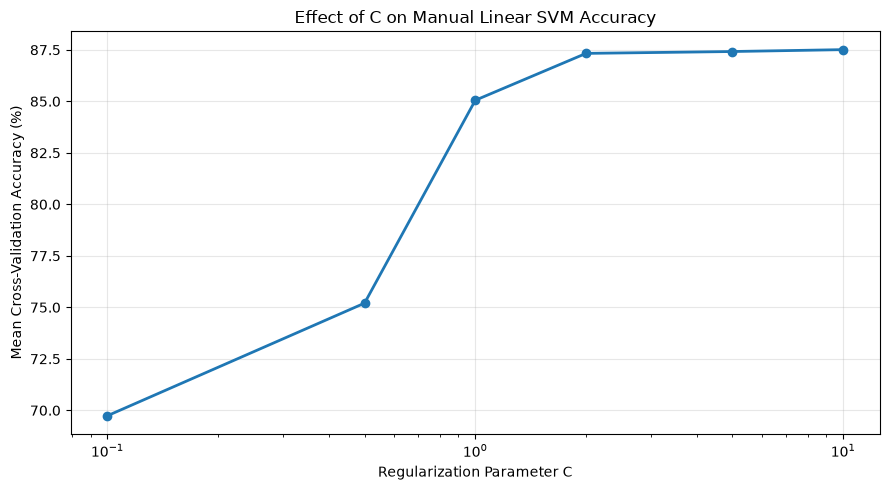

In [36]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["C"],
    results_df["CV Accuracy (%)"],
    marker="o",
    linewidth=2
)

plt.xscale("log")
plt.xlabel("Regularization Parameter C")
plt.ylabel("Mean Cross-Validation Accuracy (%)")
plt.title("Effect of C on Manual Linear SVM Accuracy")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Step 22: Effect of Learning Rate on SVM Convergence

,Learning Rate,Final Objective,Training Accuracy (%)
0,0.001,3.9422,87.876
1,0.005,3.9422,87.876
2,0.010,3.9422,87.876
3,0.050,3.9422,87.876


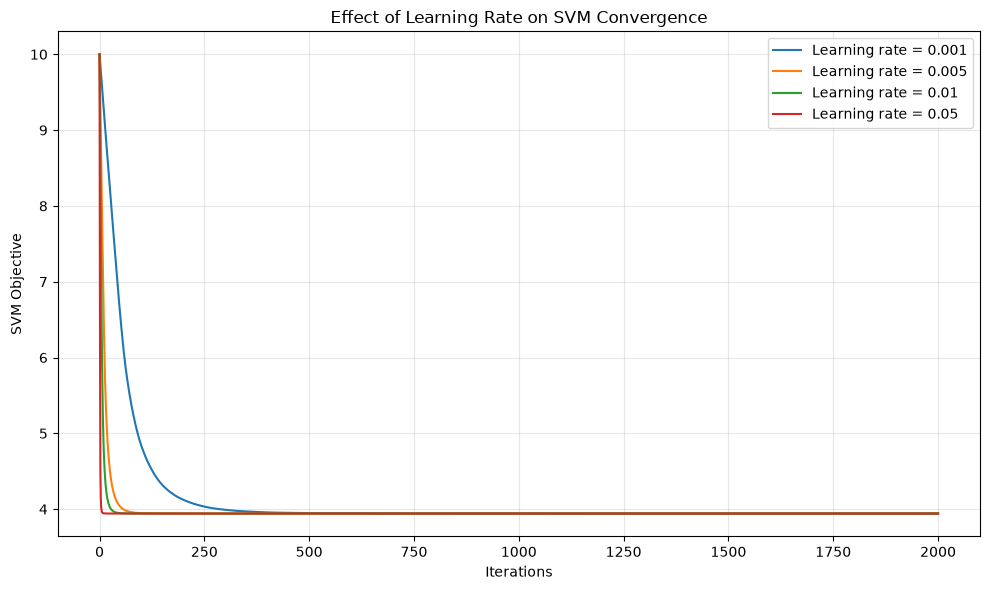

In [37]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import io
from contextlib import redirect_stdout

learning_rates = [0.001, 0.005, 0.01, 0.05]

lr_results = []
loss_histories = {}

for lr in learning_rates:

    model = LinearSVMScratch(
        learning_rate=lr,
        C=10,
        n_iters=2000
    )

    with redirect_stdout(io.StringIO()):
        model.fit(X_train_2d_svm, y_train_svm)

    predictions = model.predict(X_train_2d_svm)

    accuracy = np.mean(predictions == y_train_svm)

    lr_results.append({
        "Learning Rate": lr,
        "Final Objective": model.loss_history[-1],
        "Training Accuracy (%)": accuracy * 100
    })

    loss_histories[lr] = model.loss_history

display(pd.DataFrame(lr_results).round(4))

# Compare convergence
plt.figure(figsize=(10, 6))

for lr, history in loss_histories.items():
    plt.plot(
        history,
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("SVM Objective")
plt.title("Effect of Learning Rate on SVM Convergence")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [38]:

print("Learning Rate Convergence Analysis\n")

for lr, history in loss_histories.items():

    print(f"Learning Rate: {lr}")

    for iteration in [0, 10, 50, 100, 500, 1000, 2000]:
        print(
            f"Iteration {iteration:4d}: "
            f"Objective = {history[iteration]:.10f}"
        )

    print("-" * 45)


Learning Rate Convergence Analysis

Learning Rate: 0.001
Iteration    0: Objective = 10.0000000000
Iteration   10: Objective = 9.2720728302
Iteration   50: Objective = 6.5153485386
Iteration  100: Objective = 4.8322286995
Iteration  500: Objective = 3.9481513792
Iteration 1000: Objective = 3.9425534637
Iteration 2000: Objective = 3.9422205310
---------------------------------------------
Learning Rate: 0.005
Iteration    0: Objective = 10.0000000000
Iteration   10: Objective = 6.5061925943
Iteration   50: Objective = 4.0287323598
Iteration  100: Objective = 3.9477849005
Iteration  500: Objective = 3.9422209700
Iteration 1000: Objective = 3.9422207433
Iteration 2000: Objective = 3.9422209257
---------------------------------------------
Learning Rate: 0.01
Iteration    0: Objective = 10.0000000000
Iteration   10: Objective = 4.7790005660
Iteration   50: Objective = 3.9473029948
Iteration  100: Objective = 3.9424828147
Iteration  500: Objective = 3.9422210341
Iteration 1000: Objective = 

## Step 23: Effect of Training Iterations on Linear SVM Performance

In [39]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import io
from contextlib import redirect_stdout

iteration_values = [100, 250, 500, 1000, 2000, 4000]

iteration_results = []
iteration_histories = {}

for n_iters in iteration_values:

    model = LinearSVMScratch(
        learning_rate=0.005,
        C=10,
        n_iters=n_iters
    )

    with redirect_stdout(io.StringIO()):
        model.fit(X_train_2d_svm, y_train_svm)

    predictions = model.predict(X_train_2d_svm)

    train_accuracy = np.mean(
        predictions == y_train_svm
    )

    iteration_results.append({
        "Iterations": n_iters,
        "Final Objective": model.loss_history[-1],
        "Training Accuracy (%)": train_accuracy * 100,
        "Weight Norm": np.linalg.norm(model.w)
    })

    iteration_histories[n_iters] = model.loss_history

iteration_df = pd.DataFrame(iteration_results)

display(iteration_df.round(6))


,Iterations,Final Objective,Training Accuracy (%),Weight Norm
0,100,3.947785,88.058341,1.133319
1,250,3.942250,87.876026,1.177268
2,500,3.942221,87.876026,1.178824
3,1000,3.942221,87.876026,1.178850
4,2000,3.942221,87.876026,1.178869
5,4000,3.942221,87.876026,1.178884


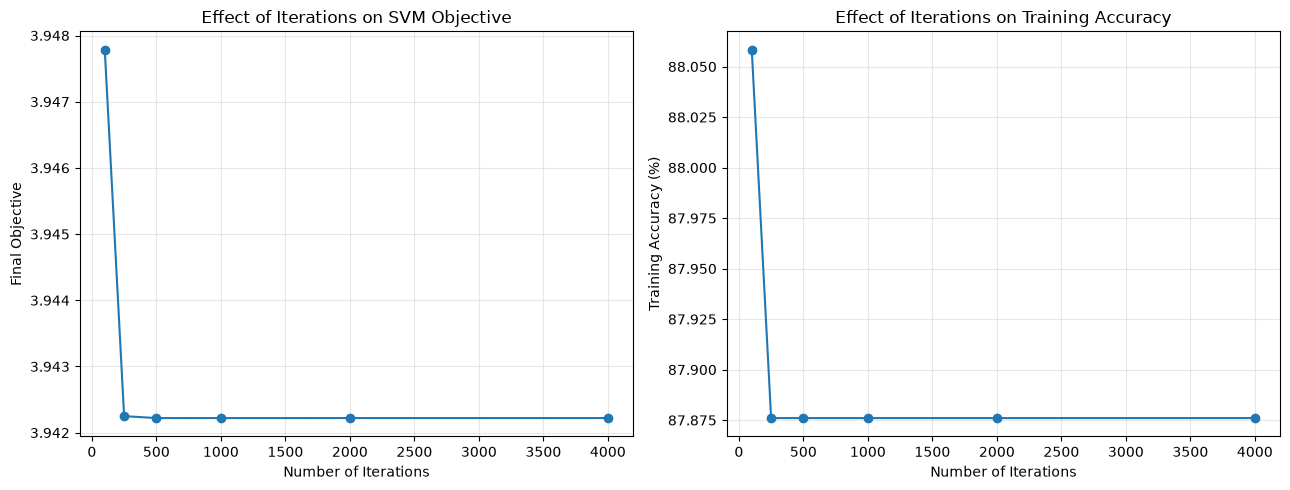

In [40]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Objective versus iterations
axes[0].plot(
    iteration_df["Iterations"],
    iteration_df["Final Objective"],
    marker="o"
)

axes[0].set_title("Effect of Iterations on SVM Objective")
axes[0].set_xlabel("Number of Iterations")
axes[0].set_ylabel("Final Objective")
axes[0].grid(alpha=0.3)

# Training accuracy versus iterations
axes[1].plot(
    iteration_df["Iterations"],
    iteration_df["Training Accuracy (%)"],
    marker="o"
)

axes[1].set_title("Effect of Iterations on Training Accuracy")
axes[1].set_xlabel("Number of Iterations")
axes[1].set_ylabel("Training Accuracy (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Step 24: Manual Linear SVM vs Scikit-learn Linear SVM

In [41]:

import numpy as np
import pandas as pd
import time
import io

from contextlib import redirect_stdout
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Use all four standardized features
# X_train_svm, X_test_svm, y_train_svm, y_test_svm
# were already created in Step 13.

C_manual = 10.0
learning_rate = 0.005
n_iters = 2000

# ---------- Manual Linear SVM ----------

manual_svm_final = LinearSVMScratch(
    learning_rate=learning_rate,
    C=C_manual,
    n_iters=n_iters
)

start = time.perf_counter()

with redirect_stdout(io.StringIO()):
    manual_svm_final.fit(X_train_svm, y_train_svm)

manual_train_time = time.perf_counter() - start

start = time.perf_counter()
manual_predictions = manual_svm_final.predict(X_test_svm)
manual_predict_time = time.perf_counter() - start


# ---------- Scikit-learn Linear SVM ----------

C_sklearn = C_manual / len(y_train_svm)

sklearn_svm = SVC(
    kernel="linear",
    C=C_sklearn,
    tol=1e-6
)

start = time.perf_counter()
sklearn_svm.fit(X_train_svm, y_train_svm)
sklearn_train_time = time.perf_counter() - start

start = time.perf_counter()
sklearn_predictions = sklearn_svm.predict(X_test_svm)
sklearn_predict_time = time.perf_counter() - start


# ---------- Compare performance ----------

results = []

for name, predictions, train_time, pred_time in [
    (
        "Manual Linear SVM",
        manual_predictions,
        manual_train_time,
        manual_predict_time
    ),
    (
        "Scikit-learn Linear SVM",
        sklearn_predictions,
        sklearn_train_time,
        sklearn_predict_time
    )
]:

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test_svm, predictions
        ),
        "Precision": precision_score(
            y_test_svm, predictions
        ),
        "Recall": recall_score(
            y_test_svm, predictions
        ),
        "F1-score": f1_score(
            y_test_svm, predictions
        ),
        "Training Time (s)": train_time,
        "Prediction Time (s)": pred_time
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

print(
    "Prediction disagreements:",
    np.sum(manual_predictions != sklearn_predictions)
)

print(
    "\nManual objective:",
    manual_svm_final.loss_history[-1]
)

print(
    "Scikit-learn objective:",
    svm_objective(
        X_train_svm,
        y_train_svm,
        sklearn_svm.coef_.ravel(),
        sklearn_svm.intercept_[0],
        C=C_manual
    )
)

print("\nManual weights:", manual_svm_final.w)
print("Sklearn weights:", sklearn_svm.coef_.ravel())


,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Linear SVM,0.9709,0.9385,1.0,0.9683,0.1825,0.0016
1,Scikit-learn Linear SVM,0.9709,0.9385,1.0,0.9683,0.0402,0.0043


Prediction disagreements: 0

Manual objective: 2.7250408296232793
Scikit-learn objective: 2.7250404500511096

Manual weights: [-1.08720541 -0.90512842 -0.79801608  0.07349626]
Sklearn weights: [-1.08718989 -0.90505646 -0.79786982  0.07346862]


## Step 25: Generating Nonlinear Data Using make_moons

Dataset shape: (500, 2)
Training shape: (400, 2)
Testing shape: (100, 2)


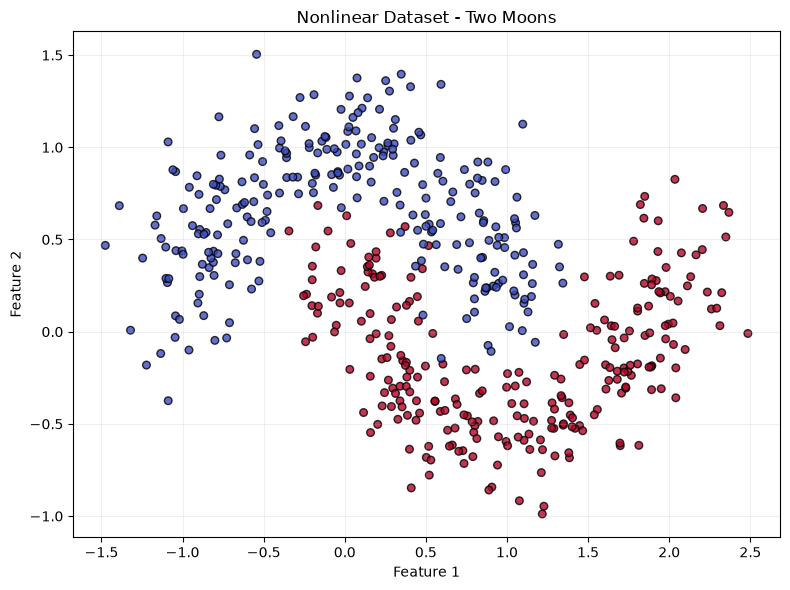

In [42]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Generate nonlinear dataset
X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.20,
    random_state=42
)

# Split into training and testing
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.20,
    random_state=42,
    stratify=y_moons
)

print("Dataset shape:", X_moons.shape)
print("Training shape:", X_moons_train.shape)
print("Testing shape:", X_moons_test.shape)

# Visualize
plt.figure(figsize=(8, 6))

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    cmap="coolwarm",
    edgecolors="black",
    s=30,
    alpha=0.8
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Dataset - Two Moons")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## Step 26: Training Linear, Polynomial and RBF Kernel SVMs

In [43]:

import numpy as np
import pandas as pd

from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define the three SVM models
models = {
    "Linear SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=1.0)
    ),

    "Polynomial SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="poly",
            degree=3,
            C=1.0,
            gamma="scale",
            coef0=1.0
        )
    ),

    "RBF SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        )
    )
}

results = []

for name, model in models.items():

    # Train the model
    model.fit(X_moons_train, y_moons_train)

    # Predictions
    train_pred = model.predict(X_moons_train)
    test_pred = model.predict(X_moons_test)

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(
            y_moons_train, train_pred
        ),
        "Test Accuracy": accuracy_score(
            y_moons_test, test_pred
        ),
        "Precision": precision_score(
            y_moons_test, test_pred
        ),
        "Recall": recall_score(
            y_moons_test, test_pred
        ),
        "F1-score": f1_score(
            y_moons_test, test_pred
        ),
        "Support Vectors": len(
            model.named_steps["svc"].support_
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,Support Vectors
0,Linear SVM,0.8625,0.86,0.8462,0.88,0.8627,124
1,Polynomial SVM,0.9700,0.99,1.0000,0.98,0.9899,73
2,RBF SVM,0.9675,0.99,1.0000,0.98,0.9899,91


## Step 27: Comparing Linear, Polynomial and RBF Decision Boundaries

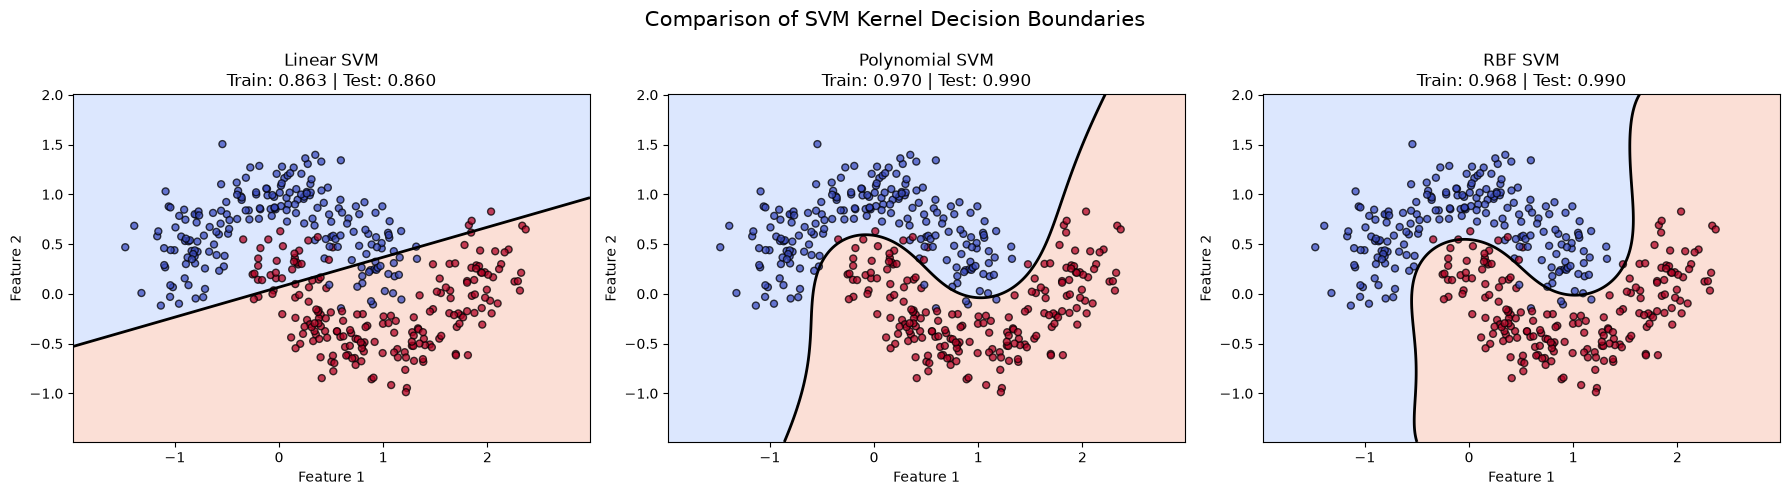

In [44]:

import numpy as np
import matplotlib.pyplot as plt

# Create plotting grid in original feature space
x_min = X_moons[:, 0].min() - 0.5
x_max = X_moons[:, 0].max() + 0.5

y_min = X_moons[:, 1].min() - 0.5
y_max = X_moons[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5)
)

for ax, (name, model) in zip(axes, models.items()):

    # Predictions across the grid
    Z = model.predict(grid_points).reshape(xx.shape)

    # Decision function for boundary line
    scores = model.decision_function(
        grid_points
    ).reshape(xx.shape)

    # Background decision regions
    ax.contourf(
        xx, yy, Z,
        levels=[-0.5, 0.5, 1.5],
        cmap="coolwarm",
        alpha=0.3
    )

    # Decision boundary at score = 0
    ax.contour(
        xx, yy, scores,
        levels=[0],
        colors="black",
        linewidths=2
    )

    # Training observations
    ax.scatter(
        X_moons_train[:, 0],
        X_moons_train[:, 1],
        c=y_moons_train,
        cmap="coolwarm",
        edgecolors="black",
        s=25,
        alpha=0.75
    )

    # Calculate training accuracy
    train_acc = accuracy_score(
        y_moons_train,
        model.predict(X_moons_train)
    )

    # Calculate test accuracy
    test_acc = accuracy_score(
        y_moons_test,
        model.predict(X_moons_test)
    )

    ax.set_title(
        f"{name}\n"
        f"Train: {train_acc:.3f} | Test: {test_acc:.3f}"
    )

    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.suptitle(
    "Comparison of SVM Kernel Decision Boundaries",
    fontsize=15
)

plt.tight_layout()
plt.show()


## Step 28: Final Comparison of Decision Tree and SVM Models

In [47]:

import numpy as np
import pandas as pd
import time
import io

from contextlib import redirect_stdout
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Same train-test split for every model
X_tr_tree = X_train.to_numpy(dtype=float)
X_te_tree = X_test.to_numpy(dtype=float)

y_tr = y_train.to_numpy()
y_te = y_test.to_numpy()

# For SVM, reuse standardized 4D data
# X_train_svm, X_test_svm
# y_train_svm, y_test_svm


# Retrieve hyperparameters from our optimized manual tree
tree_params = {
    "max_depth": optimized_tree.max_depth,
    "min_samples_split": optimized_tree.min_samples_split,
    "min_samples_leaf": optimized_tree.min_samples_leaf
}

print("Selected Decision Tree Parameters:")
print(tree_params)


C_manual = 10.0
C_sklearn = C_manual / len(y_train_svm)

models_final = [
    (
        "Manual Decision Tree",
        DecisionTreeScratch(**tree_params),
        X_tr_tree, y_tr, X_te_tree,
        False
    ),
    (
        "Scikit-learn Decision Tree",
        DecisionTreeClassifier(
            criterion="gini",
            random_state=42,
            **tree_params
        ),
        X_tr_tree, y_tr, X_te_tree,
        False
    ),
    (
        "Manual Linear SVM",
        LinearSVMScratch(
            learning_rate=0.005,
            C=C_manual,
            n_iters=2000
        ),
        X_train_svm, y_train_svm, X_test_svm,
        True
    ),
    (
        "Scikit-learn Linear SVM",
        SVC(
            kernel="linear",
            C=C_sklearn,
            tol=1e-6
        ),
        X_train_svm, y_train_svm, X_test_svm,
        True
    ),
    (
        "RBF SVM",
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        ),
        X_train_svm, y_train_svm, X_test_svm,
        True
    )
]

final_results = []

for name, model, Xtr, ytr, Xte, svm_labels in models_final:

    # Measure training time
    start = time.perf_counter()

    with redirect_stdout(io.StringIO()):
        model.fit(Xtr, ytr)

    training_time = time.perf_counter() - start

    # Measure prediction time
    start = time.perf_counter()
    predictions = model.predict(Xte)
    prediction_time = time.perf_counter() - start

    # Convert SVM labels from {-1, +1} back to {0, 1}
    if svm_labels:
        predictions = np.where(predictions == -1, 0, 1)

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_te, predictions),
        "Precision": precision_score(y_te, predictions),
        "Recall": recall_score(y_te, predictions),
        "F1-score": f1_score(y_te, predictions),
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

final_df = pd.DataFrame(final_results)

display(final_df.round(4))


Selected Decision Tree Parameters:
{'max_depth': 8, 'min_samples_split': 2, 'min_samples_leaf': 1}


,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Decision Tree,0.9818,0.9756,0.9836,0.9796,0.9439,0.0012
1,Scikit-learn Decision Tree,0.9855,0.9758,0.9918,0.9837,0.0107,0.0006
2,Manual Linear SVM,0.9709,0.9385,1.0000,0.9683,0.1392,0.0001
3,Scikit-learn Linear SVM,0.9709,0.9385,1.0000,0.9683,0.0099,0.0016
4,RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0037,0.0018


## Step 29: Final Model Performance Visualization

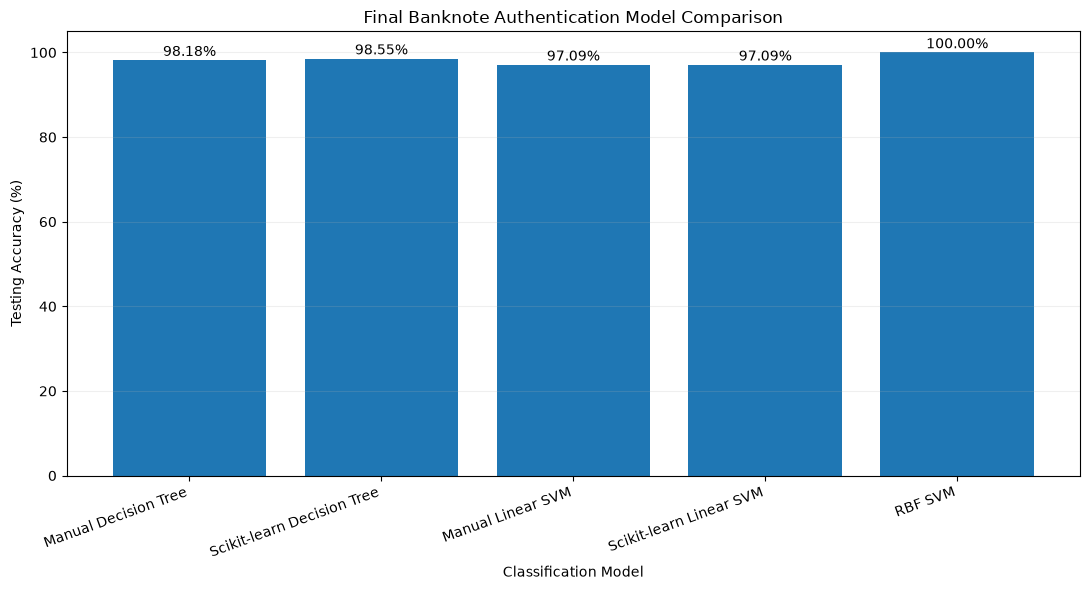

In [48]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.bar(
    final_df["Model"],
    final_df["Accuracy"] * 100
)

plt.xticks(rotation=20, ha="right")
plt.ylabel("Testing Accuracy (%)")
plt.xlabel("Classification Model")
plt.title("Final Banknote Authentication Model Comparison")

plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.2)

for i, accuracy in enumerate(final_df["Accuracy"]):
    plt.text(
        i,
        accuracy * 100 + 1,
        f"{accuracy * 100:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


## Step 30: RBF SVM Cross-Validation and Generalization Analysis

In [50]:

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_score
)

# Use original unscaled training data
X_cv = X_train.copy()
y_cv = y_train.copy()

# Keep identical feature vectors in the same fold
groups_cv = pd.factorize(
    pd.MultiIndex.from_frame(X_cv)
)[0]

# Scaling happens separately within each fold
rbf_pipeline = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )
)

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    rbf_pipeline,
    X_cv,
    y_cv,
    groups=groups_cv,
    cv=cv,
    scoring="accuracy"
)

print("RBF SVM Cross-Validation Results")
print("--------------------------------")

for i, score in enumerate(scores, start=1):
    print(f"Fold {i}: {score * 100:.2f}%")

print(f"\nMean CV Accuracy: {scores.mean() * 100:.2f}%")
print(f"CV Standard Deviation: {scores.std() * 100:.2f}%")


RBF SVM Cross-Validation Results
--------------------------------
Fold 1: 100.00%
Fold 2: 100.00%
Fold 3: 100.00%
Fold 4: 100.00%
Fold 5: 100.00%

Mean CV Accuracy: 100.00%
CV Standard Deviation: 0.00%


## Step 31: Final Observations, Model Complexity and Generalization Analysis

Final findings
1. The manually implemented Decision Tree achieved 98.18% accuracy after tuning, demonstrating effective recursive splitting using Gini impurity.
2. The manually implemented Linear SVM achieved 97.09% accuracy and produced the same test predictions as Scikit-learn, with nearly identical model weights and objective values.
3. On the Two Moons dataset, the Polynomial and RBF kernels achieved 99% accuracy, compared with 86% for the Linear kernel.
4. On the Banknote dataset, RBF SVM achieved 100% held-out test accuracy and 100% accuracy on all five cross-validation folds.
5. Manual implementations generally required more training time than optimized Scikit-learn implementations.
6. Model complexity must be controlled using stopping criteria, regularization, and validation rather than training accuracy alone.